In [1]:

import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load_csv(filename):
    with open(filename, "r", newline="") as file:
        reader = csv.reader(file)
        headers = next(reader)
        data = list(reader)

    df = pd.DataFrame(data, columns=headers)
    df = df.apply(pd.to_numeric)

    return df

train_df = load_csv("mnist_train.csv")
test_df = load_csv("mnist_test.csv")

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())
display(test_df.head())


Training shape: (60000, 785)
Test shape: (10000, 785)


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Number of pixel features: 784
Number of classes: 10
Pixel minimum: 0
Pixel maximum: 255
Mean pixel intensity: 33.318421449829934
Standard deviation: 78.56748998339798


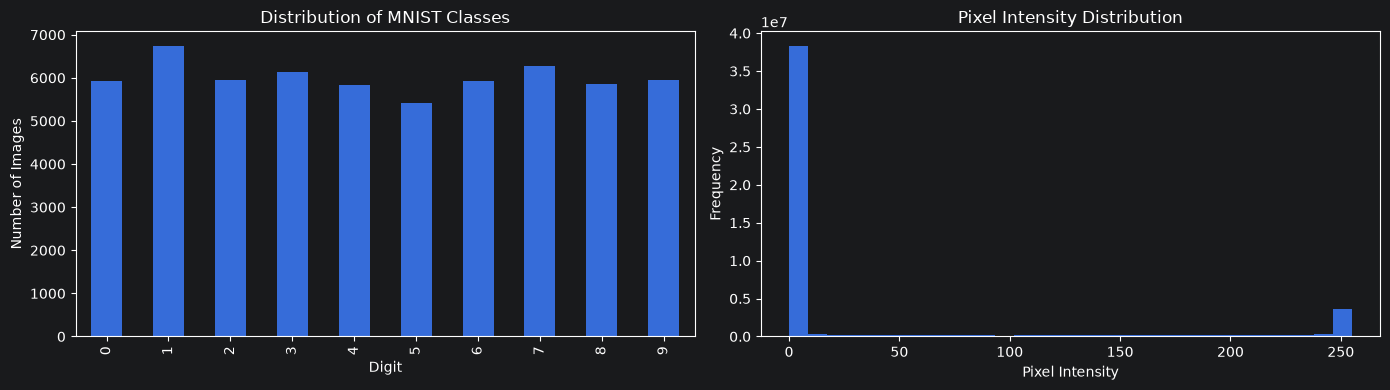

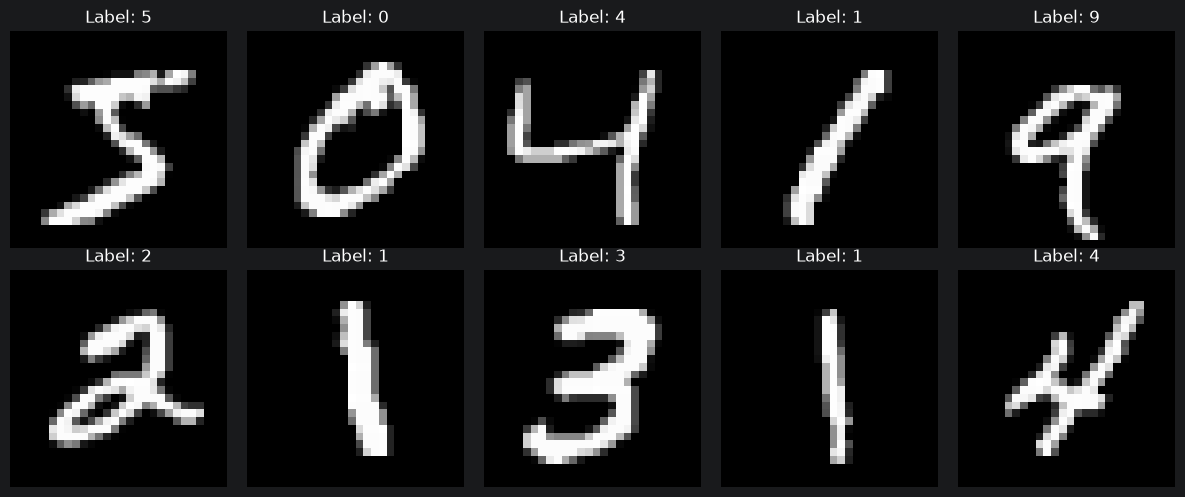

In [2]:

pixel_cols = [c for c in train_df.columns if c != "label"]

print("Number of pixel features:", len(pixel_cols))
print("Number of classes:", train_df["label"].nunique())
print("Pixel minimum:", train_df[pixel_cols].min().min())
print("Pixel maximum:", train_df[pixel_cols].max().max())
print("Mean pixel intensity:", train_df[pixel_cols].to_numpy().mean())
print("Standard deviation:", train_df[pixel_cols].to_numpy().std())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

train_df["label"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Distribution of MNIST Classes")
axes[0].set_xlabel("Digit")
axes[0].set_ylabel("Number of Images")

axes[1].hist(
    train_df[pixel_cols].to_numpy().ravel(),
    bins=30
)
axes[1].set_title("Pixel Intensity Distribution")
axes[1].set_xlabel("Pixel Intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        train_df.iloc[i][pixel_cols].to_numpy().reshape(28, 28),
        cmap="gray"
    )
    ax.set_title(f"Label: {train_df.iloc[i]['label']}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [3]:

from sklearn.model_selection import train_test_split

X_all = train_df[pixel_cols].to_numpy(dtype=np.float32) / 255.0
y_all = train_df["label"].to_numpy(dtype=np.int64)

test_pixel_cols = [c for c in test_df.columns if c != "label"]

#if "label" not in test_df.columns:
 #   raise ValueError("The test CSV must contain a label column for evaluation.")

#if set(test_pixel_cols) != set(pixel_cols):
 #   raise ValueError("Training and test pixel columns do not match.")

X_test = test_df[pixel_cols].to_numpy(dtype=np.float32) / 255.0
y_test = test_df["label"].to_numpy(dtype=np.int64)
#validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Training: (48000, 784) (48000,)
Validation: (12000, 784) (12000,)
Test: (10000, 784) (10000,)


In [4]:

def relu(Z):
    return np.maximum(0, Z)


def relu_derivative(Z):
    return (Z > 0).astype(np.float32)


def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)


def cross_entropy_loss(y, probabilities):
    probabilities = np.clip(probabilities, 1e-12, 1.0)
    return -np.mean(np.log(probabilities[np.arange(len(y)), y]))


def initialize_parameters(input_size, hidden_size, output_size, seed=42):
    rng = np.random.default_rng(seed)

    W1 = (
        rng.standard_normal((input_size, hidden_size)).astype(np.float32)
        * np.sqrt(2.0 / input_size)
    )
    b1 = np.zeros((1, hidden_size), dtype=np.float32)

    W2 = (
        rng.standard_normal((hidden_size, output_size)).astype(np.float32)
        * np.sqrt(2.0 / hidden_size)
    )
    b2 = np.zeros((1, output_size), dtype=np.float32)

    return W1, b1, W2, b2


def forward_propagation(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2
    A2 = softmax(Z2)

    return A2, (X, Z1, A1, A2)


def backpropagation(y, cache, W1, W2, l2):
    X, Z1, A1, A2 = cache
    m = len(y)

    Y = np.zeros_like(A2)
    Y[np.arange(m), y] = 1.0

    dZ2 = (A2 - Y) / m
    dW2 = A1.T @ dZ2 + (l2 / m) * W2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dZ1 = (dZ2 @ W2.T) * relu_derivative(Z1)
    dW1 = X.T @ dZ1 + (l2 / m) * W1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2


def predict_proba(X, params, batch_size=2048):
    W1, b1, W2, b2 = params
    outputs = []

    for start in range(0, len(X), batch_size):
        probabilities, _ = forward_propagation(
            X[start:start + batch_size], W1, b1, W2, b2
        )
        outputs.append(probabilities)

    return np.vstack(outputs)


def predict(X, params):
    return np.argmax(predict_proba(X, params), axis=1)


In [5]:

def train_ann(
    X_train, y_train, X_val, y_val,
    hidden_size=128,
    learning_rate=0.01,
    batch_size=128,
    l2=0.0,
    momentum=0.9,
    epochs=15,
    patience=3,
    seed=42
):
    params = initialize_parameters(
        X_train.shape[1], hidden_size, 10, seed
    )
    W1, b1, W2, b2 = params

    velocities = [
        np.zeros_like(p) for p in params
    ]

    rng = np.random.default_rng(seed)
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_params = None
    best_epoch = 0
    waiting = 0

    for epoch in range(epochs):
        indices = rng.permutation(len(X_train))

        for start in range(0, len(X_train), batch_size):
            batch_indices = indices[start:start + batch_size]
            xb = X_train[batch_indices]
            yb = y_train[batch_indices]

            probabilities, cache = forward_propagation(
                xb, W1, b1, W2, b2
            )

            gradients = backpropagation(
                yb, cache, W1, W2, l2
            )

            parameters = [W1, b1, W2, b2]

            for i in range(4):
                velocities[i] = (
                    momentum * velocities[i]
                    + gradients[i]
                )
                parameters[i] -= learning_rate * velocities[i]

            W1, b1, W2, b2 = parameters

        current_params = (W1, b1, W2, b2)

        train_probs = predict_proba(X_train, current_params)
        val_probs = predict_proba(X_val, current_params)

        train_loss = cross_entropy_loss(y_train, train_probs)
        val_loss = cross_entropy_loss(y_val, val_probs)

        train_loss += (
            l2 / (2 * len(y_train))
        ) * (np.sum(W1 ** 2) + np.sum(W2 ** 2))

        val_loss += (
            l2 / (2 * len(y_val))
        ) * (np.sum(W1 ** 2) + np.sum(W2 ** 2))

        train_acc = np.mean(np.argmax(train_probs, axis=1) == y_train)
        val_acc = np.mean(np.argmax(val_probs, axis=1) == y_val)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1:02d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Train acc: {train_acc:.4f} | "
            f"Val acc: {val_acc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_params = tuple(p.copy() for p in current_params)
            best_epoch = epoch + 1
            waiting = 0
        else:
            waiting += 1

        if waiting >= patience:
            print("Early stopping.")
            break

    return best_params, history, best_epoch


In [6]:

param_grid = []

for hidden_size in [64, 128, 256]:
    for lr in [0.01, 0.03]:
        for l2 in [0.0, 0.0001, 0.001]:
            param_grid.append((hidden_size, lr, l2))

rng = np.random.default_rng(123)

train_indices = rng.permutation(len(X_train))[:15000]
val_indices = rng.permutation(len(X_val))[:5000]

X_tune = X_train[train_indices]
y_tune = y_train[train_indices]

X_val_tune = X_val[val_indices]
y_val_tune = y_val[val_indices]

tuning_results = []

for hidden_size, lr, l2 in param_grid:

    print(
        f"\nHidden neurons: {hidden_size}, "
        f"Learning rate: {lr}, L2: {l2}"
    )

    params, hist, best_epoch = train_ann(
        X_tune,
        y_tune,
        X_val_tune,
        y_val_tune,
        hidden_size=hidden_size,
        learning_rate=lr,
        batch_size=128,
        l2=l2,
        momentum=0.9,
        epochs=5,
        patience=2,
        seed=42
    )

    val_probs = predict_proba(X_val_tune, params)
    val_predictions = np.argmax(val_probs, axis=1)

    val_accuracy = np.mean(val_predictions == y_val_tune)
    val_error = 1 - val_accuracy
    val_loss = cross_entropy_loss(y_val_tune, val_probs)

    tuning_results.append({
        "hidden_size": hidden_size,
        "learning_rate": lr,
        "batch_size": 128,
        "l2": l2,
        "best_epoch": best_epoch,
        "validation_accuracy": val_accuracy,
        "validation_error": val_error,
        "validation_cross_entropy": val_loss
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "validation_cross_entropy",
    ascending=True
).reset_index(drop=True)

print("\nHyperparameter comparison:")
display(tuning_df)

best_config = tuning_df.iloc[0]

best_hidden_size = int(best_config["hidden_size"])
best_learning_rate = float(best_config["learning_rate"])
best_batch_size = int(best_config["batch_size"])
best_l2 = float(best_config["l2"])

print("\nBest configuration:")
print("Hidden neurons:", best_hidden_size)
print("Learning rate:", best_learning_rate)
print("Batch size:", best_batch_size)
print("L2 regularization:", best_l2)
print("Best epoch:", int(best_config["best_epoch"]))
print("Validation accuracy:", round(best_config["validation_accuracy"] * 100, 2), "%")
print("Validation error:", round(best_config["validation_error"] * 100, 2), "%")
print("Validation cross-entropy:", round(best_config["validation_cross_entropy"], 5))



Hidden neurons: 64, Learning rate: 0.01, L2: 0.0
Epoch 01 | Train loss: 0.4594 | Val loss: 0.4518 | Train acc: 0.8717 | Val acc: 0.8784
Epoch 02 | Train loss: 0.3550 | Val loss: 0.3543 | Train acc: 0.8998 | Val acc: 0.9000
Epoch 03 | Train loss: 0.3127 | Val loss: 0.3178 | Train acc: 0.9135 | Val acc: 0.9084
Epoch 04 | Train loss: 0.2861 | Val loss: 0.2965 | Train acc: 0.9215 | Val acc: 0.9180
Epoch 05 | Train loss: 0.2659 | Val loss: 0.2786 | Train acc: 0.9270 | Val acc: 0.9236

Hidden neurons: 64, Learning rate: 0.01, L2: 0.0001
Epoch 01 | Train loss: 0.4594 | Val loss: 0.4518 | Train acc: 0.8717 | Val acc: 0.8784
Epoch 02 | Train loss: 0.3550 | Val loss: 0.3543 | Train acc: 0.8999 | Val acc: 0.9000
Epoch 03 | Train loss: 0.3127 | Val loss: 0.3178 | Train acc: 0.9135 | Val acc: 0.9088
Epoch 04 | Train loss: 0.2861 | Val loss: 0.2965 | Train acc: 0.9215 | Val acc: 0.9182
Epoch 05 | Train loss: 0.2659 | Val loss: 0.2786 | Train acc: 0.9271 | Val acc: 0.9236

Hidden neurons: 64, Learni

,hidden_size,learning_rate,batch_size,l2,best_epoch,validation_accuracy,validation_error,validation_cross_entropy
0,256,0.03,128,0.0010,5,0.9488,0.0512,0.181159
1,256,0.03,128,0.0000,5,0.9482,0.0518,0.181200
2,256,0.03,128,0.0001,5,0.9484,0.0516,0.181521
3,128,0.03,128,0.0000,5,0.9514,0.0486,0.182876
4,128,0.03,128,0.0001,5,0.9520,0.0480,0.183067
5,128,0.03,128,0.0010,5,0.9510,0.0490,0.183263
6,64,0.03,128,0.0001,5,0.9420,0.0580,0.209527
7,64,0.03,128,0.0010,5,0.9422,0.0578,0.209604
8,64,0.03,128,0.0000,5,0.9414,0.0586,0.209982
9,256,0.01,128,0.0000,5,0.9268,0.0732,0.257592



Best configuration:
Hidden neurons: 256
Learning rate: 0.03
Batch size: 128
L2 regularization: 0.001
Best epoch: 5
Validation accuracy: 94.88 %
Validation error: 5.12 %
Validation cross-entropy: 0.18116


In [7]:

best_config = tuning_df.iloc[0]

best_hidden_size = int(best_config["hidden_size"])
best_learning_rate = float(best_config["learning_rate"])
best_batch_size = int(best_config["batch_size"])
best_l2 = float(best_config["l2"])

print("Selected hidden neurons:", best_hidden_size)
print("Selected learning rate:", best_learning_rate)
print("Selected batch size:", best_batch_size)
print("Selected L2:", best_l2)

final_params, final_history, best_epoch = train_ann(
    X_train, y_train,
    X_val, y_val,
    hidden_size=best_hidden_size,
    learning_rate=best_learning_rate,
    batch_size=best_batch_size,
    l2=best_l2,
    momentum=0.9,
    epochs=40,
    patience=4,
    seed=42
)

print("Best epoch:", best_epoch)


Selected hidden neurons: 256
Selected learning rate: 0.03
Selected batch size: 128
Selected L2: 0.001
Epoch 01 | Train loss: 0.2162 | Val loss: 0.2344 | Train acc: 0.9381 | Val acc: 0.9339
Epoch 02 | Train loss: 0.1387 | Val loss: 0.1603 | Train acc: 0.9605 | Val acc: 0.9555
Epoch 03 | Train loss: 0.1008 | Val loss: 0.1288 | Train acc: 0.9720 | Val acc: 0.9634
Epoch 04 | Train loss: 0.0817 | Val loss: 0.1150 | Train acc: 0.9773 | Val acc: 0.9670
Epoch 05 | Train loss: 0.0697 | Val loss: 0.1061 | Train acc: 0.9808 | Val acc: 0.9691
Epoch 06 | Train loss: 0.0550 | Val loss: 0.0937 | Train acc: 0.9859 | Val acc: 0.9733
Epoch 07 | Train loss: 0.0490 | Val loss: 0.0908 | Train acc: 0.9875 | Val acc: 0.9734
Epoch 08 | Train loss: 0.0424 | Val loss: 0.0881 | Train acc: 0.9898 | Val acc: 0.9746
Epoch 09 | Train loss: 0.0360 | Val loss: 0.0837 | Train acc: 0.9916 | Val acc: 0.9768
Epoch 10 | Train loss: 0.0323 | Val loss: 0.0822 | Train acc: 0.9928 | Val acc: 0.9771
Epoch 11 | Train loss: 0.028

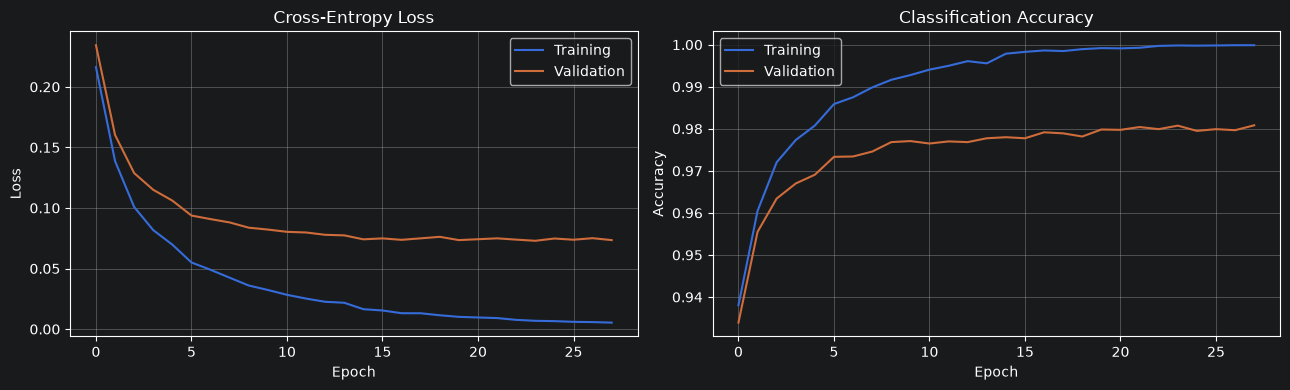

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(final_history["train_loss"], label="Training")
axes[0].plot(final_history["val_loss"], label="Validation")
axes[0].set_title("Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(final_history["train_accuracy"], label="Training")
axes[1].plot(final_history["val_accuracy"], label="Validation")
axes[1].set_title("Classification Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [9]:

test_probs = predict_proba(X_test, final_params)
y_pred = np.argmax(test_probs, axis=1)

num_classes = 10
cm = np.zeros((num_classes, num_classes), dtype=np.int64)

for actual, predicted in zip(y_test, y_pred):
    cm[actual, predicted] += 1

accuracy = np.mean(y_pred == y_test)
error_rate = 1 - accuracy

true_positive = np.diag(cm)
false_positive = cm.sum(axis=0) - true_positive
false_negative = cm.sum(axis=1) - true_positive

precision_per_class = np.divide(
    true_positive,
    true_positive + false_positive,
    out=np.zeros(num_classes, dtype=float),
    where=(true_positive + false_positive) != 0
)

recall_per_class = np.divide(
    true_positive,
    true_positive + false_negative,
    out=np.zeros(num_classes, dtype=float),
    where=(true_positive + false_negative) != 0
)

f1_per_class = np.divide(
    2 * precision_per_class * recall_per_class,
    precision_per_class + recall_per_class,
    out=np.zeros(num_classes, dtype=float),
    where=(precision_per_class + recall_per_class) != 0
)

cross_entropy = cross_entropy_loss(y_test, test_probs)

metrics = {
    "Accuracy (%)": accuracy * 100,
    "Error Rate (%)": error_rate * 100,
    "Macro Precision (%)": np.mean(precision_per_class) * 100,
    "Macro Recall (%)": np.mean(recall_per_class) * 100,
    "Macro F1-Score (%)": np.mean(f1_per_class) * 100,
    "Cross-Entropy Loss": cross_entropy
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Evaluation Metric", "Test Result"]
)

display(metrics_df.round(4))

class_metrics_df = pd.DataFrame({
    "Digit": np.arange(num_classes),
    "Precision (%)": precision_per_class * 100,
    "Recall (%)": recall_per_class * 100,
    "F1-Score (%)": f1_per_class * 100
})

display(class_metrics_df.round(3))


,Evaluation Metric,Test Result
0,Accuracy (%),98.0500
1,Error Rate (%),1.9500
2,Macro Precision (%),98.0424
3,Macro Recall (%),98.0376
4,Macro F1-Score (%),98.0394
5,Cross-Entropy Loss,0.0650


,Digit,Precision (%),Recall (%),F1-Score (%)
0,0,97.877,98.776,98.324
1,1,98.771,99.119,98.945
2,2,97.963,97.868,97.916
3,3,98.022,98.119,98.070
4,4,98.265,98.065,98.165
5,5,97.984,98.094,98.039
6,6,98.121,98.121,98.121
7,7,97.575,97.860,97.717
8,8,98.237,97.228,97.730
9,9,97.610,97.126,97.367


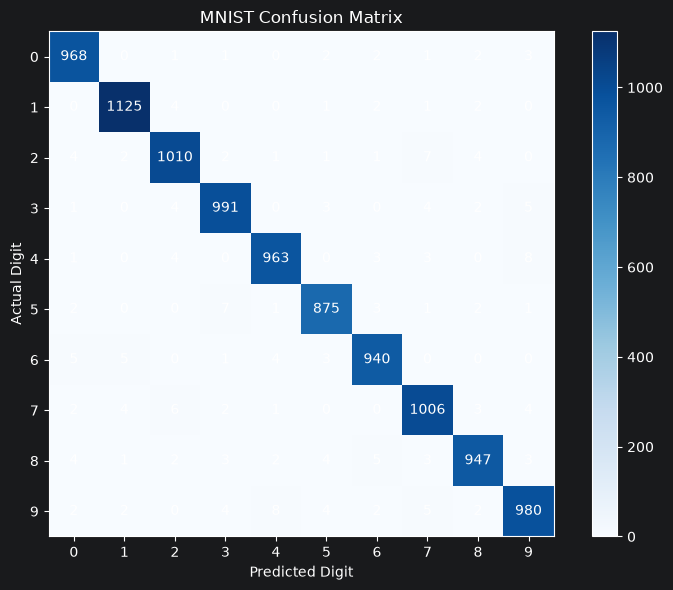

In [10]:


import numpy as np
import matplotlib.pyplot as plt

num_classes = 10

cm = np.zeros((num_classes, num_classes), dtype=np.int64)

for actual, predicted in zip(y_test, y_pred):
    cm[actual, predicted] += 1

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("MNIST Confusion Matrix")

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()


In [11]:

cm_wd = cm.copy()#without diag
np.fill_diagonal(cm_wd, 0)

confused_pairs = []

for actual in range(10):
    for predicted in range(10):
        if actual != predicted and cm[actual, predicted] > 0:
            confused_pairs.append({
                "Actual digit": actual,
                "Predicted digit": predicted,
                "Incorrect predictions": cm[actual, predicted]
            })

confused_df = pd.DataFrame(confused_pairs).sort_values(
    "Incorrect predictions", ascending=False
)

display(confused_df.head(15))


,Actual digit,Predicted digit,Incorrect predictions
30,4,9,8
62,9,4,8
32,5,3,7
18,2,7,7
45,7,2,6
38,6,0,5
56,8,6,5
65,9,7,5
39,6,1,5
25,3,9,5


,Digit,Test samples,Correct,Incorrect,Accuracy (%),Error rate (%)
0,0,980,968,12,98.776,1.224
1,1,1135,1125,10,99.119,0.881
2,2,1032,1010,22,97.868,2.132
3,3,1010,991,19,98.119,1.881
4,4,982,963,19,98.065,1.935
5,5,892,875,17,98.094,1.906
6,6,958,940,18,98.121,1.879
7,7,1028,1006,22,97.860,2.140
8,8,974,947,27,97.228,2.772
9,9,1009,980,29,97.126,2.874


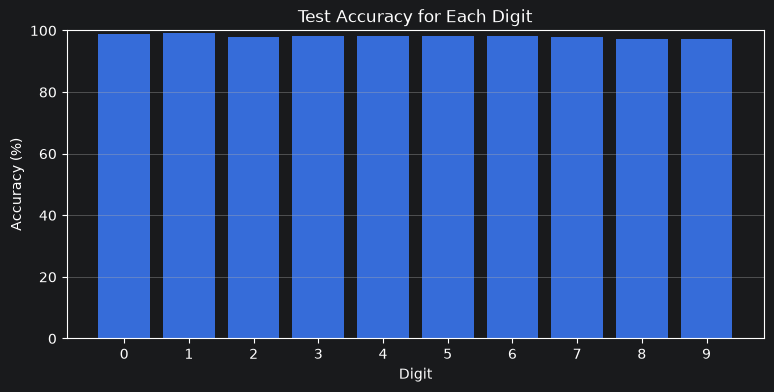

In [12]:

class_results = []

for digit in range(10):
    mask = y_test == digit
    correct = np.sum(y_pred[mask] == digit)
    total = np.sum(mask)

    class_results.append({
        "Digit": digit,
        "Test samples": total,
        "Correct": correct,
        "Incorrect": total - correct,
        "Accuracy (%)": 100 * correct / total,
        "Error rate (%)": 100 * (total - correct) / total
    })

class_results_df = pd.DataFrame(class_results)
display(class_results_df.round(3))

plt.figure(figsize=(9, 4))
plt.bar(
    class_results_df["Digit"],
    class_results_df["Accuracy (%)"]
)
plt.xlabel("Digit")
plt.ylabel("Accuracy (%)")
plt.title("Test Accuracy for Each Digit")
plt.xticks(range(10))
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()


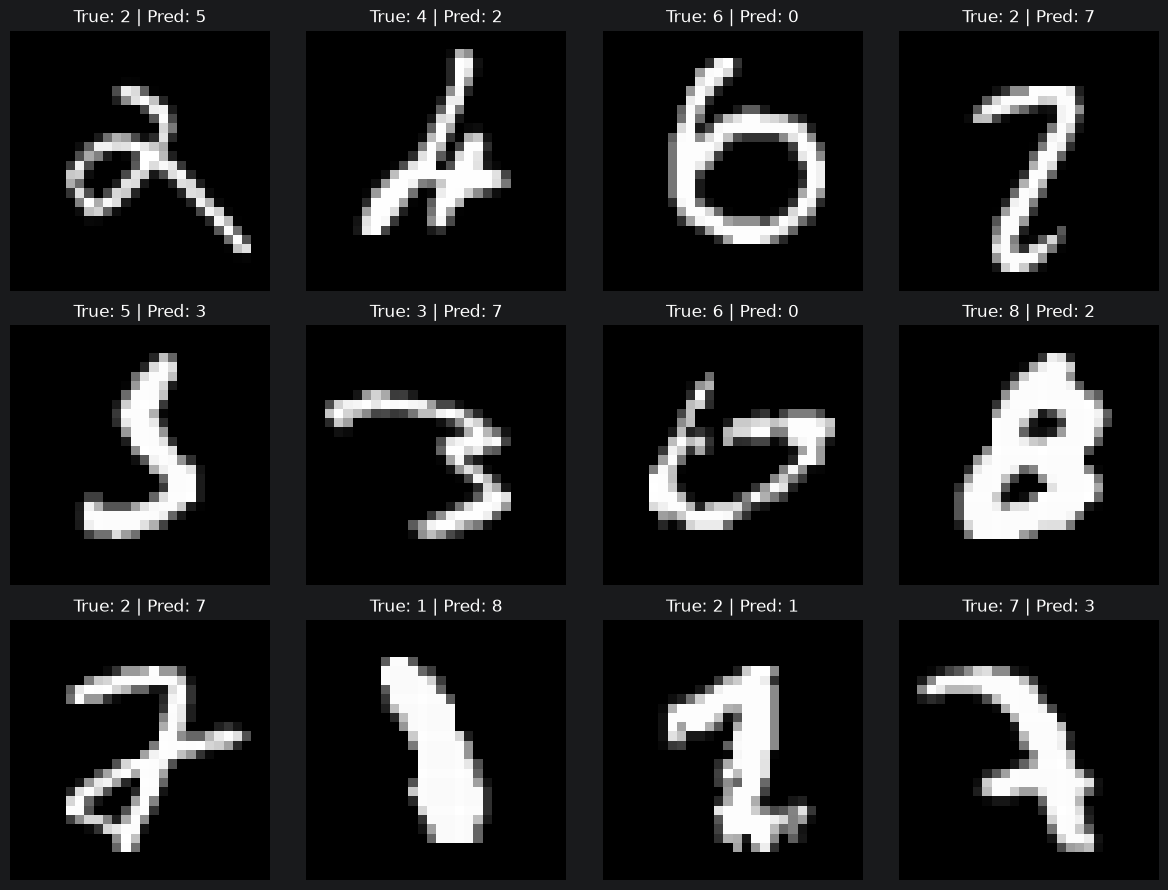

In [13]:

wrong_indices = np.where(y_pred != y_test)[0]
n_show = min(12, len(wrong_indices))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, idx in zip(axes.flat, wrong_indices[:n_show]):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"True: {y_test[idx]} | Pred: {y_pred[idx]}"
    )
    ax.axis("off")

for ax in axes.flat[n_show:]:
    ax.axis("off")

plt.tight_layout()
plt.show()
